# Density and Stratification Calculation Investigation

This notebook investigates the negative density values appearing in 2023 for the time series plots (e.g., in `process42`). 

## Findings
I have identified two major issues causing this anomaly:

1. **Data Anomaly (`salt = 0.0`)**: In 2023, the practical salinity (`salt` and `salt2`) data for certain regions (e.g., Tokyo Bay) was recorded as `0.0` instead of `NaN`. Pure water at high summer temperatures (e.g., 28°C) has a density slightly below 1000 kg/m³. Because the pipeline calculates density anomaly as `density - 1000`, the result is a negative value (e.g., -4 kg/m³), causing the sudden drop in the 2023 time series plots.
2. **Inconsistent Density Calculation Functions**: Across the pipeline, density is computed in two different ways:
   - In some scripts (like `process42` and `process43`), it is calculated as `gsw.rho(salt, wtemp, 0) - 1000`. This uses Practical Salinity and In-Situ Temperature directly in a function intended for Absolute Salinity and Conservative Temperature, which is mathematically incorrect per the TEOS-10 standard.
   - In other scripts (like `process01`), it correctly converts Practical Salinity to Absolute Salinity (`gsw.SA_from_SP`) and In-Situ Temperature to Conservative Temperature (`gsw.CT_from_t`), then uses `gsw.sigma0(SA, CT)`.

Let's explore these issues below.


In [1]:
import sys
import pandas as pd
import gsw
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('/home/reyha/SIS_Analysis_WSL')
from utils.data_loader import load_and_process_data

# Load merged data
df = load_and_process_data(force_reload=False)

# Look at 2023 data for Tokyo Bay, Summer, Surface
subset = df[(df['surveyyear'] == 2023) & (df['watermass_name'] == 'Tokyo Bay') & (df['season'] == 'Summer') & (df['saisuipoin'] == 1)].copy()

print("Descriptive statistics for Salinity (salt) in Tokyo Bay 2023:")
display(subset[['salt', 'salt2', 'wtemp']].describe())

print("\nSample rows showing salt = 0.0:")
display(subset[['surveyyear', 'salt', 'salt2', 'wtemp']].head(10))


Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Descriptive statistics for Salinity (salt) in Tokyo Bay 2023:


,salt,salt2
count,43.000000,43.000000
mean,14.626977,14.626977
std,14.725846,14.725846
min,0.000000,0.000000
25%,0.000000,0.000000
50%,13.600000,13.600000
75%,29.975000,29.975000
max,32.080000,32.080000



Sample rows showing salt = 0.0:


,surveyyear,salt,salt2,wtemp
62523,2023,0.0,0.0,28.9
62535,2023,0.0,0.0,22.0
62537,2023,0.0,0.0,21.5
62539,2023,0.0,0.0,22.0
62541,2023,0.0,0.0,22.2
62543,2023,0.0,0.0,20.6
62545,2023,0.0,0.0,20.4
62547,2023,0.0,0.0,20.2
62549,2023,0.0,0.0,22.8
62551,2023,0.0,0.0,30.6


## Density Calculation Comparison
Below, we compute the density using both the incorrect method found in `process42` and the correct TEOS-10 standard used in `process01`. Notice that both methods produce negative density anomalies when `salt` is artificially `0.0`.


In [2]:
# Calculate density the 'incorrect' way (from process42)
salt_val = pd.to_numeric(subset['salt'], errors='coerce')
wtemp = pd.to_numeric(subset['wtemp'], errors='coerce')
subset['density_incorrect'] = gsw.rho(salt_val, wtemp, 0) - 1000

# Calculate density the 'correct' way (from process01, TEOS-10)
salt2_val = pd.to_numeric(subset['salt2'], errors='coerce')
lon = subset['longitude']
lat = subset['latitude']
SA = gsw.SA_from_SP(salt2_val, 0, lon, lat)
CT = gsw.CT_from_t(SA, wtemp, 0)
subset['density_correct'] = gsw.sigma0(SA, CT)

print("Comparison of Density Calculations:")
display(subset[['wtemp', 'salt', 'density_incorrect', 'density_correct']].head(10))


Comparison of Density Calculations:


,wtemp,salt,density_incorrect,density_correct
62523,28.9,0.0,-3.621992,-4.023062
62535,22.0,0.0,-1.984853,-2.225975
62537,21.5,0.0,-1.883009,-2.113705
62539,22.0,0.0,-1.984853,-2.225975
62541,22.2,0.0,-2.026254,-2.271593
62543,20.6,0.0,-1.705715,-1.918072
62545,20.4,0.0,-1.667379,-1.875737
62547,20.2,0.0,-1.629434,-1.833821
62549,22.8,0.0,-2.152707,-2.410857
62551,30.6,0.0,-4.088090,-4.532820


## Visualization of the Issue
The plot below illustrates how `salt=0.0` creates negative density anomalies across the years.


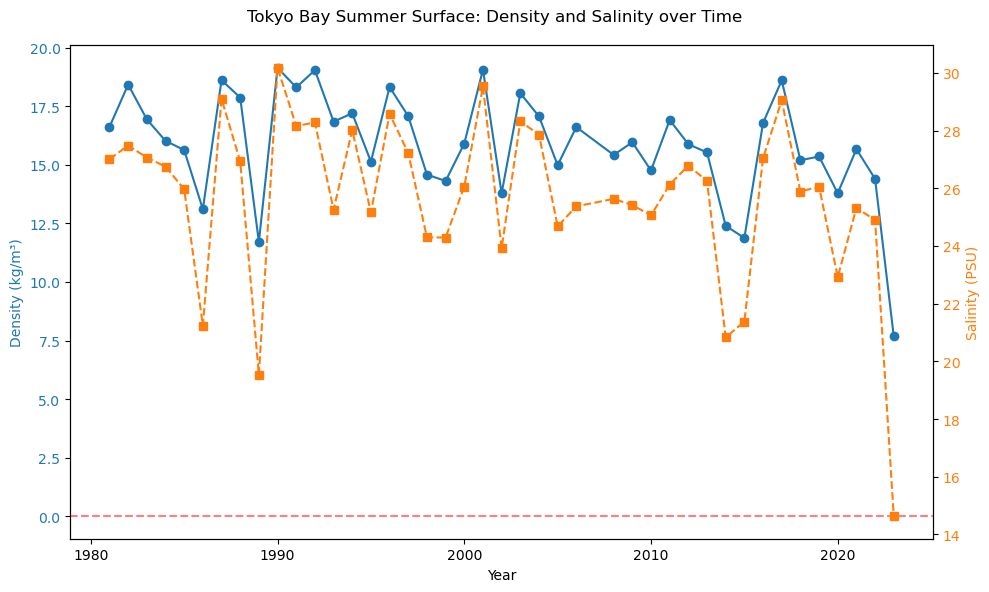

In [3]:
# Aggregate yearly mean for Tokyo Bay Surface Summer
tb = df[(df['watermass_name'] == 'Tokyo Bay') & (df['season'] == 'Summer') & (df['saisuipoin'] == 1)].copy()

# Apply the TEOS-10 calculation
tb['SA'] = gsw.SA_from_SP(pd.to_numeric(tb['salt'], errors='coerce'), 0, tb['longitude'], tb['latitude'])
tb['CT'] = gsw.CT_from_t(tb['SA'], pd.to_numeric(tb['wtemp'], errors='coerce'), 0)
tb['density'] = gsw.sigma0(tb['SA'], tb['CT'])

yearly_mean = tb.groupby('surveyyear')[['density', 'salt']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(10, 6))

color = 'tab:blue'
ax1.set_xlabel('Year')
ax1.set_ylabel('Density (kg/m³)', color=color)
ax1.plot(yearly_mean['surveyyear'], yearly_mean['density'], marker='o', color=color, label='Density')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axhline(0, color='red', linestyle='--', alpha=0.5, label='0 kg/m³')

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Salinity (PSU)', color=color)
ax2.plot(yearly_mean['surveyyear'], yearly_mean['salt'], marker='s', linestyle='--', color=color, label='Salinity')
ax2.tick_params(axis='y', labelcolor=color)

fig.suptitle('Tokyo Bay Summer Surface: Density and Salinity over Time')
fig.tight_layout()
plt.show()
